100%|██████████| 541/541 [04:53<00:00,  1.84it/s]


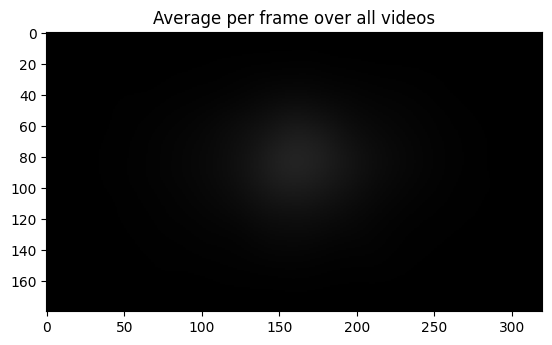

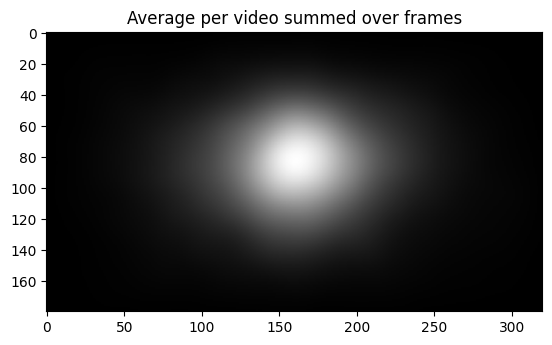

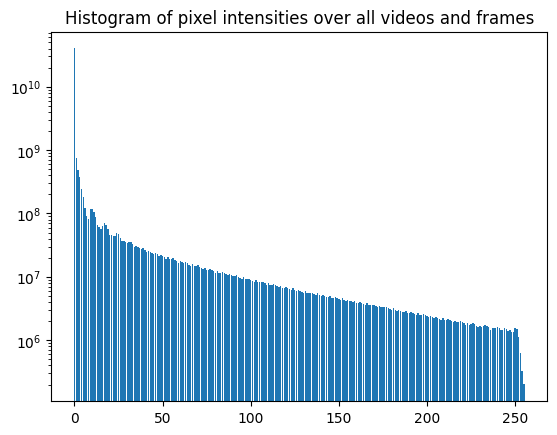

Done


In [32]:
import matplotlib.pyplot as plt 
import numpy as np 
import imageio
import os 
import tqdm

lim = None
root = "../neural_network/data/saliency_dataset_upsampled/"
files = sorted([os.path.join(root, el) for el in os.listdir(root) if os.path.isdir(os.path.join(root, el))])

if lim is not None:
    files = files[:lim]

outputs_avg_per_frame = np.zeros((180, 320, 3)).astype(np.float64)
outputs_avg_per_vid = np.zeros((180, 320, 3)).astype(np.float64)
hist_count = np.zeros((256)).astype(np.int64)
frame_count = 0
vid_count = 0


for file in tqdm.tqdm(files):
    outputs = os.path.join(file, "outputs.npz")
    outputs = np.load(outputs)['outputs'].astype(np.float64)

    summed = np.sum(outputs, axis=0)    
    
    outputs_avg_per_frame += np.mean(outputs, axis=0)
    outputs_avg_per_vid += summed
    
    frame_count += outputs.shape[0]
    vid_count += 1
    
        
    np.add.at(hist_count, outputs.flatten().astype(np.int64), 1)
    
outputs_avg_per_frame /= vid_count
outputs_avg_per_vid /= outputs_avg_per_vid.max()
outputs_avg_per_vid *= 255.0

plt.imshow(outputs_avg_per_frame.astype(np.uint8))
plt.title("Average per frame over all videos")
plt.show()

plt.imshow(outputs_avg_per_vid.astype(np.uint8))
plt.title("Average per video summed over frames")
plt.show()

plt.bar(np.arange(256), hist_count)
plt.yscale("log")
plt.title("Histogram of pixel intensities over all videos and frames")
plt.show()
print("Done")

In [35]:
total = hist_count.sum()
zeros = hist_count[0]
print(f"Total pixels: {total}, Zeros: {zeros}, Percentage of zeros: {zeros/total*100:.2f}%")


for i in range(256):
    print(f"Pixel value {i}: Count {hist_count[i]}, Percentage: {hist_count[i]/total*100:.4f}%")

Total pixels: 45617299200, Zeros: 40143956697, Percentage of zeros: 88.00%
Pixel value 0: Count 40143956697, Percentage: 88.0016%
Pixel value 1: Count 748251021, Percentage: 1.6403%
Pixel value 2: Count 493234986, Percentage: 1.0812%
Pixel value 3: Count 379469940, Percentage: 0.8319%
Pixel value 4: Count 242991174, Percentage: 0.5327%
Pixel value 5: Count 180642969, Percentage: 0.3960%
Pixel value 6: Count 123322626, Percentage: 0.2703%
Pixel value 7: Count 90920994, Percentage: 0.1993%
Pixel value 8: Count 82620090, Percentage: 0.1811%
Pixel value 9: Count 116724189, Percentage: 0.2559%
Pixel value 10: Count 115579266, Percentage: 0.2534%
Pixel value 11: Count 103654380, Percentage: 0.2272%
Pixel value 12: Count 88627563, Percentage: 0.1943%
Pixel value 13: Count 65328588, Percentage: 0.1432%
Pixel value 14: Count 62111844, Percentage: 0.1362%
Pixel value 15: Count 57409446, Percentage: 0.1259%
Pixel value 16: Count 62679441, Percentage: 0.1374%
Pixel value 17: Count 70246500, Percen

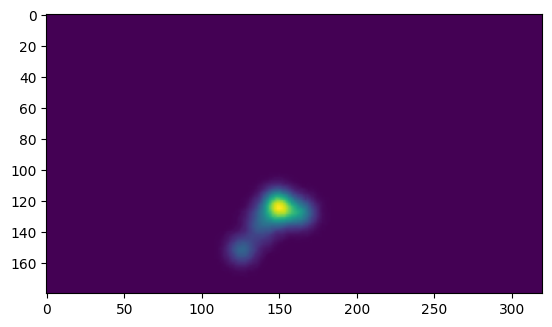

In [9]:
import numpy as np 

arr = np.load("test.npy")
arr = arr[0,0]

import matplotlib.pyplot as plt
plt.imshow(arr)
plt.show()

In [3]:
np.shape()

TypeError: shape() missing 1 required positional argument: 'a'